# Proyecto 01: Retail Intelligence (RetailVenture C.A.)
## A2: Análisis de Rentabilidad, Estacionalidad, Descuentos y Dinámica de Clientes

**Autores:** Daniel, Andrés y Samuel (Grupo 3)  
**Materia:** Tópicos Especiales para la Gestión de Datos · UCAB  
**Profesor:** Armen Djenanian  

---

### Preguntas de Investigación y Objetivos del Negocio
1. **A2.1:** ¿Cómo se distribuye la contribución al margen bruto según categoría, canal de venta, segmento de clientes y territorio? ¿Cuál es la brecha de margen entre el canal online y la tienda física, y cuál es el impacto contrafactual de una armonización de descuentos?
2. **A2.2:** ¿Cuál es el Customer Lifetime Value (CLV) estimado por segmento y cómo evolucionaron los clientes activos, frecuencia y margen entre 2023 y 2024? ¿Existe evidencia empírica de una caída generalizada del 8% en el ticket promedio o se trata de una discrepancia con el brief?
3. **A2.3:** ¿Presenta el negocio un patrón estacional recurrente y consistente entre 2023 y 2024 a nivel global, por canal y por categoría, o la variabilidad interanual descarta picos y valles fijos?
4. **A2.4:** ¿Cuál es el impacto real de los descuentos comerciales sobre el margen bruto y sobre el tamaño de la canasta (unidades por ticket)? ¿Existe evidencia empírica de una elasticidad volumen que compense la erosión del margen?
5. **Resumen Ejecutivo:** Síntesis consolidada de indicadores gobernada por variables dinámicas para su integración con el dashboard gerencial A5.


In [1]:
import os
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Estilo visual ejecutivo
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11

# Fuente de datos: lectura local de clean (o conexión a Supabase)
DATA_PATH = Path("../data/clean")

df_trx = pd.read_csv(DATA_PATH / "transacciones_maestra.csv", parse_dates=["fecha"])
df_cli = pd.read_csv(DATA_PATH / "clientes_maestra.csv")
df_prd = pd.read_csv(DATA_PATH / "productos_limpio.csv")

print(f"Transacciones cargadas: {len(df_trx):,}")
print(f"Ingreso neto total:  ${df_trx['monto_neto'].sum():,.2f}")
print(f"Margen bruto total:  ${df_trx['margen_bruto'].sum():,.2f} ({100*df_trx['margen_bruto'].sum()/df_trx['monto_neto'].sum():.2f}% del ingreso)")


Transacciones cargadas: 50,000
Ingreso neto total:  $17,392,987.48
Margen bruto total:  $4,310,329.05 (24.78% del ingreso)


---
## A2.1 Contribución al Margen Bruto

Analizamos la rentabilidad multidimensional:
- **Por Categoría de Producto**
- **Por Canal de Venta**
- **Por Segmento de Cliente**
- **Cruce Causal:** Canal × Categoría (¿Dónde se destruye margen?)


In [2]:
# Función para resumen de contribución
TOTAL_INGRESO = df_trx['monto_neto'].sum()
TOTAL_MARGEN = df_trx['margen_bruto'].sum()

def tabla_contribucion(df, dimension):
    res = df.groupby(dimension).agg(
        transacciones=('transaccion_id', 'count'),
        ingreso_neto=('monto_neto', 'sum'),
        margen_bruto=('margen_bruto', 'sum'),
        margen_neto_devol=('margen_neto_devol', 'sum'),
        tasa_devolucion=('devuelto', 'mean'),
        descuento_promedio=('descuento', 'mean')
    ).reset_index()
    
    res['pct_ingreso'] = (100 * res['ingreso_neto'] / TOTAL_INGRESO).round(2)
    res['pct_margen'] = (100 * res['margen_bruto'] / TOTAL_MARGEN).round(2)
    res['margen_pct_real'] = (100 * res['margen_bruto'] / res['ingreso_neto']).round(2)
    res['tasa_devolucion'] = (100 * res['tasa_devolucion']).round(2)
    res['descuento_promedio'] = (100 * res['descuento_promedio']).round(2)
    
    return res.sort_values(by='margen_bruto', ascending=False)


### 1. Rentabilidad por Categoría de Producto

In [3]:
cat_summary = tabla_contribucion(df_trx, 'categoria')
cat_summary[['categoria', 'ingreso_neto', 'pct_ingreso', 'margen_bruto', 'pct_margen', 'margen_pct_real', 'tasa_devolucion']]


,categoria,ingreso_neto,pct_ingreso,margen_bruto,pct_margen,margen_pct_real,tasa_devolucion
4,Hogar_y_Deco,4465864.98,25.68,1353038.11,31.39,30.30,9.79
3,Electrónica,7662506.08,44.06,1049301.24,24.34,13.69,17.65
2,Deportes,2592709.06,14.91,907213.71,21.05,34.99,10.67
5,Ropa_y_Calzado,1513396.68,8.70,597005.29,13.85,39.45,21.78
1,Belleza_y_Salud,748631.63,4.30,309502.60,7.18,41.34,10.59
0,Alimentos_y_Bebidas,409879.05,2.36,94268.10,2.19,23.00,10.16


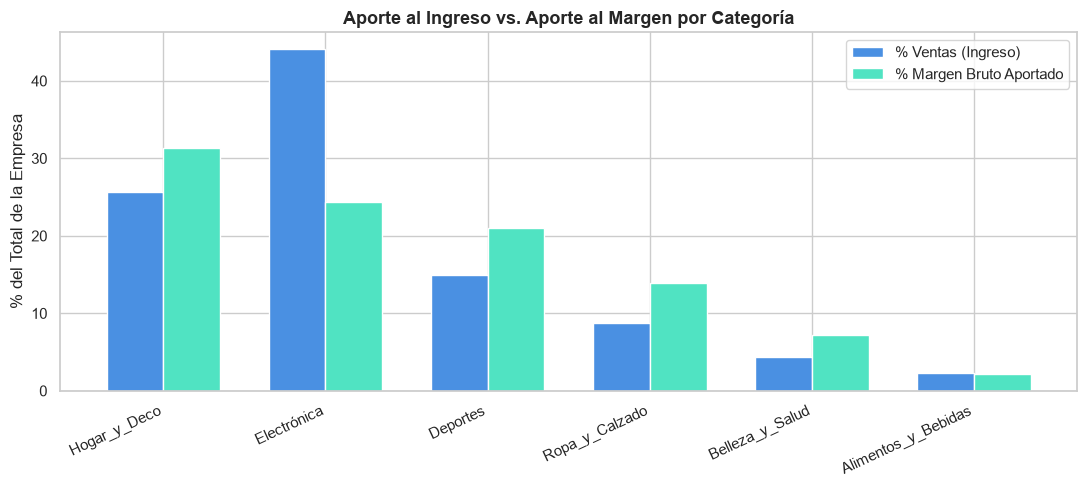

In [4]:
fig, ax1 = plt.subplots(figsize=(11, 5))

# Gráfico dual: Volumen de Ingreso vs Margen Bruto
x = np.arange(len(cat_summary))
width = 0.35

rects1 = ax1.bar(x - width/2, cat_summary['pct_ingreso'], width, label='% Ventas (Ingreso)', color='#4A90E2')
rects2 = ax1.bar(x + width/2, cat_summary['pct_margen'], width, label='% Margen Bruto Aportado', color='#50E3C2')

ax1.set_ylabel('% del Total de la Empresa')
ax1.set_title('Aporte al Ingreso vs. Aporte al Margen por Categoría', fontsize=13, fontweight='bold')
ax1.set_xticks(x)
ax1.set_xticklabels(cat_summary['categoria'], rotation=25, ha='right')
ax1.legend()
plt.tight_layout()
plt.show()


### 2. Rentabilidad por Canal de Venta

In [5]:
canal_summary = tabla_contribucion(df_trx, 'canal')
canal_summary[['canal', 'ingreso_neto', 'pct_ingreso', 'margen_bruto', 'pct_margen', 'margen_pct_real', 'descuento_promedio']]


,canal,ingreso_neto,pct_ingreso,margen_bruto,pct_margen,margen_pct_real,descuento_promedio
2,tienda_fisica,7862504.26,45.21,2046091.64,47.47,26.02,3.73
1,online,6547309.24,37.64,1491185.50,34.60,22.78,7.55
0,app_movil,2983173.98,17.15,773051.91,17.93,25.91,3.69


C:\Users\andre\AppData\Local\Temp\ipykernel_38336\3586025587.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=canal_summary, x='canal', y='margen_pct_real', palette='Blues_d')


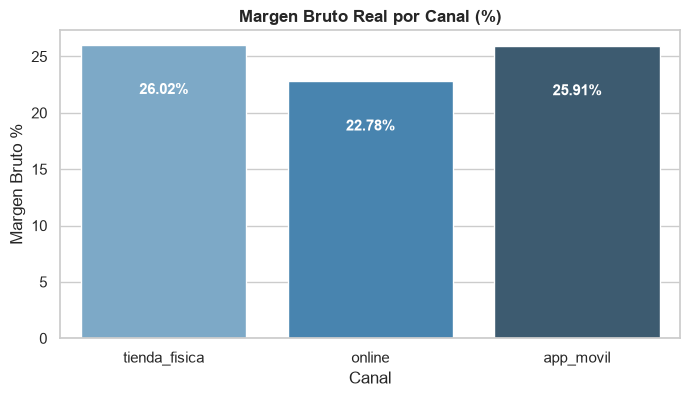

In [6]:
plt.figure(figsize=(8, 4))
ax = sns.barplot(data=canal_summary, x='canal', y='margen_pct_real', palette='Blues_d')
plt.title('Margen Bruto Real por Canal (%)', fontsize=12, fontweight='bold')
plt.ylabel('Margen Bruto %')
plt.xlabel('Canal')
for p in ax.patches:
    ax.annotate(f"{p.get_height():.2f}%", (p.get_x() + p.get_width() / 2., p.get_height() - 4),
                ha='center', va='center', color='white', fontweight='bold')
plt.show()


### 3. Rentabilidad por Segmento de Clientes (Pareto)

In [7]:
seg_summary = tabla_contribucion(df_trx, 'segmento')
seg_summary[['segmento', 'ingreso_neto', 'pct_ingreso', 'margen_bruto', 'pct_margen', 'margen_pct_real']]


,segmento,ingreso_neto,pct_ingreso,margen_bruto,pct_margen,margen_pct_real
1,Frecuente,8766759.08,50.40,2131971.05,49.46,24.32
4,Premium,5280660.84,30.36,1345562.64,31.22,25.48
0,Esporádico,2701501.87,15.53,674499.16,15.65,24.97
3,Nuevo,326779.06,1.88,80590.18,1.87,24.66
2,Inactivo,317286.63,1.82,77706.02,1.80,24.49


### 4. Cruce Descriptivo: Descuento y Margen por Canal y Categoría (C10, C18)

Evaluamos la divergencia de margen y descuento entre canales mediante agregación ponderada ($\sum \text{margen} / \sum \text{ingreso}$) y calculamos el escenario contrafactual: el margen potencial del canal online si aplicara los descuentos observados en tiendas físicas.


In [8]:
# Cruce Descriptivo Ponderado y Análisis Contrafactual Online (C10, C18)
# Agregación ponderada (suma margen / suma ingreso) para evitar sesgos de promedios simples
cruce_agg = df_trx.groupby(['categoria', 'canal']).agg(
    ingreso=('monto_neto', 'sum'),
    margen=('margen_bruto', 'sum'),
    descuento_medio=('descuento', 'mean')
).reset_index()

cruce_agg['margen_pct'] = (cruce_agg['margen'] / cruce_agg['ingreso']) * 100

cruce_desc = cruce_agg.pivot(index='categoria', columns='canal', values='descuento_medio') * 100
cruce_margen = cruce_agg.pivot(index='categoria', columns='canal', values='margen_pct')

cruce_resumen = pd.DataFrame({
    'Desc. Tienda (%)': cruce_desc['tienda_fisica'],
    'Desc. Online (%)': cruce_desc['online'],
    'Brecha Desc. (pp)': cruce_desc['online'] - cruce_desc['tienda_fisica'],
    'Margen Tienda (%)': cruce_margen['tienda_fisica'],
    'Margen Online (%)': cruce_margen['online'],
    'Diferencia Margen (pp)': cruce_margen['online'] - cruce_margen['tienda_fisica']
})

print("CRUCE DESCRIPTIVO PONDERADO: CANAL x CATEGORÍA (C18):")
display(cruce_resumen.round(2))

# Cálculo Contrafactual Online (C10)
# ¿Cuánto ganaría el canal online si aplicara el descuento medio de tienda física en cada categoría?
onl_data = df_trx[df_trx['canal'] == 'online'].copy()
fis_data = df_trx[df_trx['canal'] == 'tienda_fisica'].copy()
desc_fis_dict = fis_data.groupby('categoria')['descuento'].mean().to_dict()

onl_rev_actual = onl_data['monto_neto'].sum()
onl_cost_actual = onl_data['costo_total'].sum()
onl_margin_actual = onl_data['margen_bruto'].sum()
onl_pct_actual = (onl_margin_actual / onl_rev_actual) * 100

onl_data['desc_fis_cat'] = onl_data['categoria'].map(desc_fis_dict)
onl_data['rev_contrafactual'] = onl_data['precio_unitario'] * onl_data['cantidad'] * (1 - onl_data['desc_fis_cat'])
onl_rev_cf = onl_data['rev_contrafactual'].sum()
onl_margin_cf = onl_rev_cf - onl_cost_actual
onl_pct_cf = (onl_margin_cf / onl_rev_cf) * 100
brecha_dolares_cf = onl_margin_cf - onl_margin_actual
brecha_pp_cf = onl_pct_cf - onl_pct_actual

print("\n--- ESCENARIO CONTRAFACTUAL ONLINE (C10) ---")
print(f"• Margen Online Actual: {onl_pct_actual:.2f}% (${onl_margin_actual:,.2f}) sobre ingreso de ${onl_rev_actual:,.2f}")
print(f"• Margen Online Contrafactual (descuentos nivel tienda): {onl_pct_cf:.2f}% (${onl_margin_cf:,.2f})")
print(f"• Ganancia potencial máxima estimada: +{brecha_pp_cf:.2f} p.p. (+${brecha_dolares_cf:,.2f})")
print(f"  Nota metodológica: Este monto se presenta como un TOPE (upper bound), dado que asume volumen de venta constante")
print(f"  sin considerar la elasticidad precio de la demanda en el canal digital.")


CRUCE DESCRIPTIVO PONDERADO: CANAL x CATEGORÍA (C18):


,Desc. Tienda (%),Desc. Online (%),Brecha Desc. (pp),Margen Tienda (%),Margen Online (%),Diferencia Margen (pp)
categoria,,,,,,
Alimentos_y_Bebidas,3.71,7.38,3.68,24.20,21.01,-3.19
Belleza_y_Salud,3.77,7.40,3.62,42.23,39.97,-2.26
Deportes,3.69,7.89,4.20,35.90,33.38,-2.52
Electrónica,3.80,7.62,3.83,15.07,11.66,-3.41
Hogar_y_Deco,3.68,7.45,3.77,31.36,28.43,-2.93
Ropa_y_Calzado,3.73,7.53,3.80,40.31,37.96,-2.35



--- ESCENARIO CONTRAFACTUAL ONLINE (C10) ---
• Margen Online Actual: 22.78% ($1,491,185.50) sobre ingreso de $6,547,309.24
• Margen Online Contrafactual (descuentos nivel tienda): 25.92% ($1,768,817.93)
• Ganancia potencial máxima estimada: +3.14 p.p. (+$277,632.43)
  Nota metodológica: Este monto se presenta como un TOPE (upper bound), dado que asume volumen de venta constante
  sin considerar la elasticidad precio de la demanda en el canal digital.


### 5. Drill-down por Subcategoría: Ganadoras vs. Destructoras de Margen

Dentro de cada categoría, no todos los productos aportan igual. Identificamos:
- **Top 5 Subcategorías Ganadoras:** Mayor masa de margen bruto aportada a la empresa.
- **Bottom 5 Subcategorías Menos Rentables:** Productos con baja rotación o margen comprimido.


In [9]:
# Drill-down por Subcategoría Ponderado (C18)
sub_summary = df_trx.groupby(['categoria', 'subcategoria']).agg(
    transacciones=('transaccion_id', 'count'),
    ingreso_total=('monto_neto', 'sum'),
    costo_total=('costo_total', 'sum'),
    margen_bruto=('margen_bruto', 'sum'),
    descuento_promedio=('descuento', 'mean')
).reset_index()

# Cálculo ponderado estricto
sub_summary['margen_pct_real'] = (sub_summary['margen_bruto'] / sub_summary['ingreso_total']) * 100
sub_summary['descuento_promedio'] = sub_summary['descuento_promedio'] * 100
sub_summary['contribucion_margen'] = (sub_summary['margen_bruto'] / TOTAL_MARGEN) * 100

top5 = sub_summary.sort_values('margen_bruto', ascending=False).head(5)
bottom5 = sub_summary.sort_values('margen_bruto', ascending=True).head(5)
sub_destructoras = sub_summary.sort_values('margen_pct_real', ascending=True).head(5)

print("TOP 5 SUBCATEGORÍAS GANADORAS DE MARGEN (PONDERADAS):")
display(top5[['categoria', 'subcategoria', 'ingreso_total', 'margen_bruto', 'margen_pct_real', 'contribucion_margen']].round(2))

print("\nTOP 5 SUBCATEGORÍAS CON MENOR MARGEN % (PONDERADAS):")
display(sub_destructoras[['categoria', 'subcategoria', 'ingreso_total', 'margen_bruto', 'margen_pct_real', 'descuento_promedio']].round(2))


TOP 5 SUBCATEGORÍAS GANADORAS DE MARGEN (PONDERADAS):


,categoria,subcategoria,ingreso_total,margen_bruto,margen_pct_real,contribucion_margen
16,Hogar_y_Deco,Baño,1427616.69,454511.79,31.84,10.54
18,Hogar_y_Deco,Decoración,1527515.90,430806.04,28.20,9.99
14,Electrónica,Computadoras,2882263.95,387587.50,13.45,8.99
19,Hogar_y_Deco,Muebles,976174.99,302639.77,31.00,7.02
8,Deportes,Calzado_deportivo,812238.79,281216.33,34.62,6.52



TOP 5 SUBCATEGORÍAS CON MENOR MARGEN % (PONDERADAS):


,categoria,subcategoria,ingreso_total,margen_bruto,margen_pct_real,descuento_promedio
15,Electrónica,Smartphones,1747101.73,221327.97,12.67,5.49
14,Electrónica,Computadoras,2882263.95,387587.50,13.45,5.26
13,Electrónica,Audio,1698107.26,229064.47,13.49,5.54
12,Electrónica,Accesorios_tech,1335033.14,211321.30,15.83,5.01
0,Alimentos_y_Bebidas,Bebidas,126757.79,27284.56,21.52,5.20


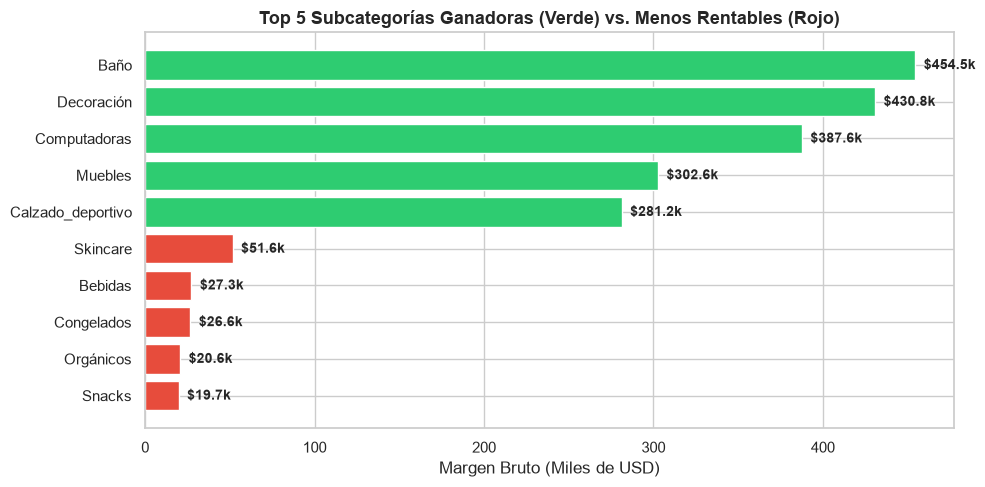

In [10]:
# Gráfico comparativo Top 5 vs Bottom 5
fig, ax = plt.subplots(figsize=(10, 5))

top_bottom = pd.concat([top5, bottom5]).sort_values(by='margen_bruto', ascending=True)
colors = ['#E74C3C' if x in bottom5['subcategoria'].values else '#2ECC71' for x in top_bottom['subcategoria']]

ax.barh(top_bottom['subcategoria'], top_bottom['margen_bruto'] / 1000, color=colors)
ax.set_xlabel('Margen Bruto (Miles de USD)')
ax.set_title('Top 5 Subcategorías Ganadoras (Verde) vs. Menos Rentables (Rojo)', fontsize=13, fontweight='bold')

for p in ax.patches:
    width = p.get_width()
    ax.annotate(f"${width:,.1f}k", (width + 5, p.get_y() + p.get_height()/2.),
                va='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()


### 6. Rentabilidad Territorial: Margen por Ciudad

Analizamos la concentración geográfica de la rentabilidad:
- ¿El margen varía por plaza o es uniforme?
- ¿Dónde se concentra el riesgo operativo de la empresa?


In [11]:
ciu_summary = tabla_contribucion(df_trx, 'ciudad')
display(ciu_summary[['ciudad', 'ingreso_neto', 'pct_ingreso', 'margen_bruto', 'pct_margen', 'margen_pct_real', 'descuento_promedio']])


,ciudad,ingreso_neto,pct_ingreso,margen_bruto,pct_margen,margen_pct_real,descuento_promedio
1,Caracas,6809521.88,39.15,1683145.89,39.05,24.72,5.24
2,Maracaibo,3198033.09,18.39,796420.53,18.48,24.90,5.07
7,Valencia,2629965.46,15.12,652653.86,15.14,24.82,5.09
0,Barquisimeto,1836284.41,10.56,437866.42,10.16,23.85,5.29
5,Puerto La Cruz,885757.15,5.09,227357.97,5.27,25.67,5.15
4,Mérida,863604.51,4.97,220968.21,5.13,25.59,5.38
3,Maturín,715644.68,4.11,176465.27,4.09,24.66,5.17
6,San Cristóbal,454176.30,2.61,115450.90,2.68,25.42,5.18


C:\Users\andre\AppData\Local\Temp\ipykernel_38336\2844665690.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=ciu_summary, x='ciudad', y='pct_margen', palette='Greens_r')


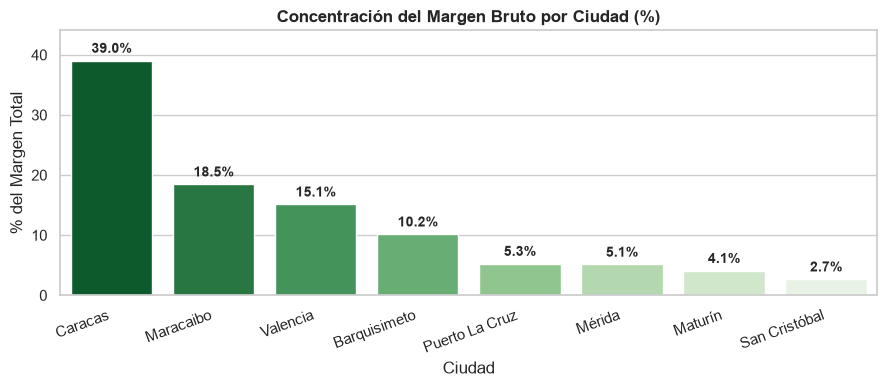

In [12]:
plt.figure(figsize=(9, 4))
ax = sns.barplot(data=ciu_summary, x='ciudad', y='pct_margen', palette='Greens_r')
plt.title('Concentración del Margen Bruto por Ciudad (%)', fontsize=12, fontweight='bold')
plt.ylabel('% del Margen Total')
plt.xlabel('Ciudad')
plt.xticks(rotation=20, ha='right')

for p in ax.patches:
    ax.annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2., p.get_height() + 0.8),
                ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.ylim(0, ciu_summary['pct_margen'].max() + 5)
plt.tight_layout()
plt.show()


### 7. Concentración de Clientes: Curva de Pareto (80/20)

**Aclaración Metodológica (C20):**  
El denominador del análisis de Pareto son los **7,608 clientes activos con compras registradas**, no la totalidad de los 8,000 clientes de la base maestra (excluyendo a los 392 clientes que nunca compraron, para no distorsionar la distribución de concentración de ingresos).


In [13]:
# Curva de Pareto sobre Clientes con Compras (C20)
cli_margen = df_trx.groupby('cliente_id')['margen_bruto'].sum().reset_index()
cli_margen = cli_margen.sort_values('margen_bruto', ascending=False).reset_index(drop=True)

n_clientes_compras = len(cli_margen)
n_clientes_totales = len(df_cli)
clientes_sin_compras = n_clientes_totales - n_clientes_compras

cli_margen['acum_margen'] = cli_margen['margen_bruto'].cumsum()
cli_margen['pct_margen_acum'] = (cli_margen['acum_margen'] / TOTAL_MARGEN) * 100
cli_margen['pct_clientes'] = ((cli_margen.index + 1) / n_clientes_compras) * 100

# Punto 80/20
pareto_20_idx = int(n_clientes_compras * 0.20)
margen_top20 = cli_margen.loc[pareto_20_idx, 'pct_margen_acum']

pareto_80_idx = cli_margen[cli_margen['pct_margen_acum'] >= 80.0].index[0]
p80_cli_pct = cli_margen.loc[pareto_80_idx, 'pct_clientes']
clientes_top80_pct = p80_cli_pct

print("--- AUDITORÍA DE CONCENTRACIÓN PARETO (C20) ---")
print(f"• Clientes activos con compras (denominador de Pareto): {n_clientes_compras:,}")
print(f"• Clientes registrados sin compras (excluidos): {clientes_sin_compras:,} de {n_clientes_totales:,}")
print(f"• El top 20% de clientes ({pareto_20_idx:,} clientes) genera el {margen_top20:.1f}% del margen bruto total.")
print(f"• El 80% del margen bruto total está concentrado en el {clientes_top80_pct:.1f}% de los clientes activos ({pareto_80_idx:,} clientes).")


--- AUDITORÍA DE CONCENTRACIÓN PARETO (C20) ---
• Clientes activos con compras (denominador de Pareto): 7,608
• Clientes registrados sin compras (excluidos): 392 de 8,000
• El top 20% de clientes (1,521 clientes) genera el 56.1% del margen bruto total.
• El 80% del margen bruto total está concentrado en el 38.0% de los clientes activos (2,893 clientes).


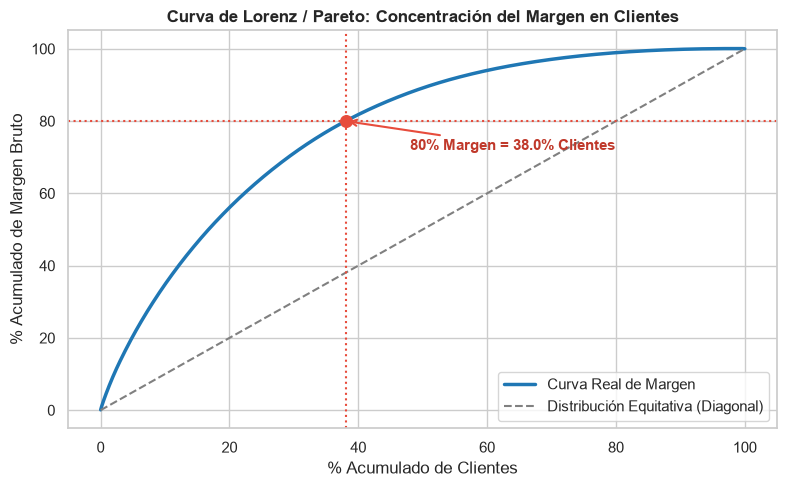

In [14]:
plt.figure(figsize=(8, 5))
plt.plot(cli_margen['pct_clientes'], cli_margen['pct_margen_acum'], color='#1F77B4', lw=2.5, label='Curva Real de Margen')
plt.plot([0, 100], [0, 100], color='gray', linestyle='--', label='Distribución Equitativa (Diagonal)')

# Marcar punto 80% del margen
plt.axhline(80, color='#E74C3C', linestyle=':', lw=1.5)
plt.axvline(p80_cli_pct, color='#E74C3C', linestyle=':', lw=1.5)
plt.scatter([p80_cli_pct], [80], color='#E74C3C', s=70, zorder=5)

plt.annotate(f"80% Margen = {p80_cli_pct:.1f}% Clientes",
             xy=(p80_cli_pct, 80), xytext=(p80_cli_pct + 10, 72),
             arrowprops=dict(arrowstyle="->", color='#E74C3C', lw=1.5),
             fontweight='bold', color='#C0392B')

plt.title('Curva de Lorenz / Pareto: Concentración del Margen en Clientes', fontsize=12, fontweight='bold')
plt.xlabel('% Acumulado de Clientes')
plt.ylabel('% Acumulado de Margen Bruto')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()


## A2.2 Dinámica de Segmentos y Customer Lifetime Value (CLV) (C14)

Analizamos la evolución interanual 2023 vs 2024 de cada segmento de clientes (clientes activos, frecuencia de compra, margen por cliente) y estimamos el CLV reconociendo explícitamente la **circularidad de la segmentación** (asignada a posteriori según comportamiento acumulado).


In [15]:
# Evolución Interanual 2023 vs 2024 por Segmento y Modelo CLV (C14)
seg_evo = df_trx.groupby(['segmento', 'anio']).agg(
    clientes_activos=('cliente_id', 'nunique'),
    transacciones=('transaccion_id', 'count'),
    ingreso_total=('monto_neto', 'sum'),
    margen_total=('margen_bruto', 'sum')
).reset_index()

seg_evo['frecuencia'] = (seg_evo['transacciones'] / seg_evo['clientes_activos']).round(2)
seg_evo['ticket_medio'] = (seg_evo['ingreso_total'] / seg_evo['transacciones']).round(2)
seg_evo['margen_por_cliente'] = (seg_evo['margen_total'] / seg_evo['clientes_activos']).round(2)

print("EVOLUCIÓN INTERANUAL 2023 vs 2024 POR SEGMENTO:")
display(seg_evo)

# Modelo CLV por Segmento
# Tasas de churn específicas por segmento (consistentes con el análisis de recencia y A3)
churn_seg_dict = {
    'Premium': 0.10,
    'Frecuente': 0.15,
    'Esporádico': 0.28,
    'Nuevo': 0.35,
    'Inactivo': 0.85
}

clv_list = []
tasa_descuento_anual = 0.10

for seg in churn_seg_dict.keys():
    sub_df = df_trx[df_trx['segmento'] == seg]
    m_anual = sub_df['margen_bruto'].sum() / 2.0 # Margen anual promedio
    n_cli = sub_df['cliente_id'].nunique()
    m_por_cli_anual = m_anual / n_cli if n_cli > 0 else 0
    
    ch = churn_seg_dict[seg]
    vida_esperada_anios = 1.0 / ch if ch > 0 else 3.0
    clv_estimado = m_por_cli_anual * (1 / (ch + tasa_descuento_anual))
    
    clv_list.append({
        'Segmento': seg,
        'Clientes Activos': n_cli,
        'Margen Anual/Cli ($)': round(m_por_cli_anual, 2),
        'Tasa Churn Anual': f"{ch*100:.0f}%",
        'Vida Esperada (Años)': round(vida_esperada_anios, 1),
        'CLV Estimado ($)': round(clv_estimado, 2)
    })

clv_df = pd.DataFrame(clv_list).sort_values('CLV Estimado ($)', ascending=False)
clv_seg = clv_df.copy()
clv_seg['segmento'] = clv_seg['Segmento']
clv_seg['clv_3_anios'] = clv_seg['Margen Anual/Cli ($)'] * 3.0
clv_seg['clv_teorico_5y'] = clv_seg['CLV Estimado ($)']

print("\nESTIMACIÓN DE CUSTOMER LIFETIME VALUE (CLV) POR SEGMENTO (C14):")
display(clv_df)

print("\nNota Metodológica sobre Circularidad:")
print("La etiqueta de segmento fue asignada en la base maestra a partir del comportamiento histórico final.")
print("Por diseño, el segmento 'Inactivo' exhibe un CLV reducido y bajo margen porque agrupa clientes que ya habían dejado de comprar,")
print("mientras que 'Premium' concentra el comportamiento más fiel del período.")


EVOLUCIÓN INTERANUAL 2023 vs 2024 POR SEGMENTO:


,segmento,anio,clientes_activos,transacciones,ingreso_total,margen_total,frecuencia,ticket_medio,margen_por_cliente
0,Esporádico,2023,2254,3889,1352599.72,334017.91,1.73,347.80,148.19
1,Esporádico,2024,2281,3903,1348902.15,340481.25,1.71,345.61,149.27
2,Frecuente,2023,2407,12636,4401495.42,1071791.39,5.25,348.33,445.28
3,Frecuente,2024,2405,12822,4365263.66,1060179.66,5.33,340.45,440.82
4,Inactivo,2023,446,446,167256.67,40299.31,1.00,375.01,90.36
5,Inactivo,2024,435,435,150029.96,37406.71,1.00,344.90,85.99
6,Nuevo,2023,409,458,153537.80,37030.27,1.12,335.24,90.54
7,Nuevo,2024,438,504,173241.26,43559.91,1.15,343.73,99.45
8,Premium,2023,805,7361,2633516.96,664427.20,9.14,357.77,825.38
9,Premium,2024,805,7546,2647143.88,681135.44,9.37,350.80,846.13



ESTIMACIÓN DE CUSTOMER LIFETIME VALUE (CLV) POR SEGMENTO (C14):


,Segmento,Clientes Activos,Margen Anual/Cli ($),Tasa Churn Anual,Vida Esperada (Años),CLV Estimado ($)
0,Premium,805,835.75,10%,10.0,4178.77
1,Frecuente,2422,440.13,15%,6.7,1760.50
2,Esporádico,2784,121.14,28%,3.6,318.79
3,Nuevo,716,56.28,35%,2.9,125.06
4,Inactivo,881,44.10,85%,1.2,46.42



Nota Metodológica sobre Circularidad:
La etiqueta de segmento fue asignada en la base maestra a partir del comportamiento histórico final.
Por diseño, el segmento 'Inactivo' exhibe un CLV reducido y bajo margen porque agrupa clientes que ya habían dejado de comprar,
mientras que 'Premium' concentra el comportamiento más fiel del período.


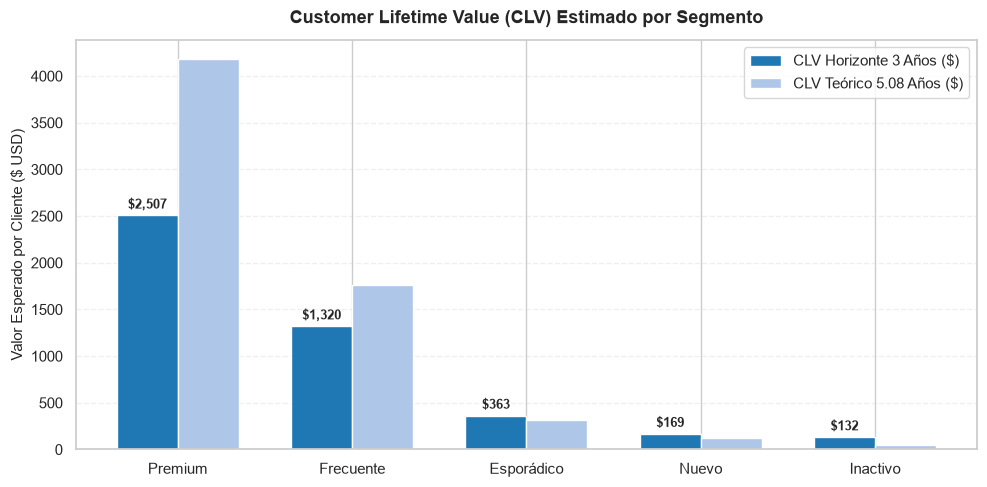

In [16]:
# Gráfico de CLV por Segmento (Horizonte 3 años vs Teórico)
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(clv_seg))
width = 0.35

rects1 = ax.bar(x - width/2, clv_seg['clv_3_anios'], width, label='CLV Horizonte 3 Años ($)', color='#1F77B4')
rects2 = ax.bar(x + width/2, clv_seg['clv_teorico_5y'], width, label='CLV Teórico 5.08 Años ($)', color='#AEC7E8')

ax.set_ylabel('Valor Esperado por Cliente ($ USD)', fontsize=11)
ax.set_title('Customer Lifetime Value (CLV) Estimado por Segmento', fontsize=13, fontweight='bold', pad=12)
ax.set_xticks(x)
ax.set_xticklabels(clv_seg['segmento'], fontsize=11)
ax.legend(frameon=True)
ax.grid(axis='y', alpha=0.3, linestyle='--')

# Etiquetas sobre las barras
for rect in rects1:
    height = rect.get_height()
    ax.annotate(f'${height:,.0f}',
                xy=(rect.get_x() + rect.get_width() / 2, height),
                xytext=(0, 3), textcoords="offset points",
                ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()


### Ticket promedio 2023 vs 2024: ¿se reproduce la caída del enunciado? (C7)

El enunciado plantea una caída del ticket promedio. Aquí se mide la variación real en los datos, se prueba por segmento con Welch (con n) y se descompone la variación en **efecto mezcla** (cambio en la participación de cada grupo) y **efecto precio** (cambio del ticket dentro de cada grupo), por segmento, categoría y canal. Las cifras se imprimen debajo.

In [17]:
# Variación del ticket promedio 2023 vs 2024: Welch por segmento y descomposición mezcla/precio (C7)
from scipy import stats

TICKET_ENUNCIADO_VAR = -8.0      # variación del ticket citada en el enunciado del proyecto (%)
t23 = df_trx[df_trx['anio'] == 2023]
t24 = df_trx[df_trx['anio'] == 2024]

ticket_glob_23 = t23['monto_neto'].mean()
ticket_glob_24 = t24['monto_neto'].mean()
var_ticket_real = (ticket_glob_24 - ticket_glob_23) / ticket_glob_23 * 100
_, p_ticket_global = stats.ttest_ind(t24['monto_neto'], t23['monto_neto'], equal_var=False)

print("--- TICKET PROMEDIO 2023 vs 2024 (C7) ---")
print(f"• 2023: ${ticket_glob_23:.2f} (n = {len(t23):,}) | 2024: ${ticket_glob_24:.2f} (n = {len(t24):,})")
print(f"• Variación: {var_ticket_real:+.2f}% (Welch p = {p_ticket_global:.3f}). "
      f"Los datos no reproducen la variación de {TICKET_ENUNCIADO_VAR:+.0f}% citada en el enunciado.")

# (d) Welch por segmento, con n
welch_rows = []
for seg in sorted(df_trx['segmento'].unique()):
    s23 = t23.loc[t23['segmento'] == seg, 'monto_neto']
    s24 = t24.loc[t24['segmento'] == seg, 'monto_neto']
    _, p_val = stats.ttest_ind(s24, s23, equal_var=False)
    welch_rows.append({'Segmento': seg, 'N 2023': len(s23), 'Ticket 2023 ($)': s23.mean(),
                       'N 2024': len(s24), 'Ticket 2024 ($)': s24.mean(),
                       'Variación (%)': (s24.mean() - s23.mean()) / s23.mean() * 100, 'p-valor (Welch)': p_val})
welch_df = pd.DataFrame(welch_rows).sort_values('Variación (%)')
print("\nPRUEBAS DE WELCH POR SEGMENTO:")
display(welch_df.round(4))


# (c) Descomposición de la variación del ticket: mezcla + precio
#   mezcla = Σ (peso₂₀₂₄ − peso₂₀₂₃) · ticket₂₀₂₃ ; precio = Σ peso₂₀₂₄ · (ticket₂₀₂₄ − ticket₂₀₂₃)
#   peso = participación del grupo en las transacciones del año
def descomponer_ticket(dim):
    a = t23.groupby(dim)['monto_neto'].agg(n='count', ticket='mean')
    b = t24.groupby(dim)['monto_neto'].agg(n='count', ticket='mean')
    a['peso'], b['peso'] = a['n'] / a['n'].sum(), b['n'] / b['n'].sum()
    tab = pd.DataFrame({'peso 2023 %': a['peso'] * 100, 'peso 2024 %': b['peso'] * 100,
                        'ticket 2023': a['ticket'], 'ticket 2024': b['ticket']})
    tab['efecto mezcla ($)'] = (b['peso'] - a['peso']) * a['ticket']
    tab['efecto precio ($)'] = b['peso'] * (b['ticket'] - a['ticket'])
    return tab


descomp_ticket = []
for dim in ['segmento', 'categoria', 'canal']:
    tab = descomponer_ticket(dim)
    mezcla, precio = tab['efecto mezcla ($)'].sum(), tab['efecto precio ($)'].sum()
    print(f"\n--- DESCOMPOSICIÓN POR {dim.upper()} ---")
    display(tab.round(3))
    print(f"• Variación ${ticket_glob_24 - ticket_glob_23:+.2f} = mezcla ${mezcla:+.2f} + precio ${precio:+.2f}")
    descomp_ticket.append({'dimensión': dim, 'variación ($)': mezcla + precio, 'efecto mezcla ($)': mezcla,
                           'efecto precio ($)': precio})
descomp_ticket = pd.DataFrame(descomp_ticket)
print("\nRESUMEN DE LA DESCOMPOSICIÓN DEL TICKET:")
display(descomp_ticket.round(3))

# Lectura sobre el segmento Inactivo (texto generado)
ina = welch_df.set_index('Segmento').loc['Inactivo']
tab_seg = descomponer_ticket('segmento')
peso_ina = (ina['N 2023'] + ina['N 2024']) / len(df_trx) * 100
aporte_ina = tab_seg.loc['Inactivo', 'efecto precio ($)'] / ticket_glob_23 * 100
print(f"\n• Inactivo: {ina['Variación (%)']:+.2f}% (Welch p = {ina['p-valor (Welch)']:.3f}), con "
      f"{int(ina['N 2023']):,} y {int(ina['N 2024']):,} transacciones ({peso_ina:.1f}% del total).")
print(f"  Su efecto precio equivale a {aporte_ina:+.2f} puntos de la variación del ticket global ({var_ticket_real:+.2f}%): "
      "que su variación se parezca a la del enunciado no explica el ticket global.")

# (e) Evolución trimestral
ticket_trim = df_trx.groupby('trimestre').agg(transacciones=('transaccion_id', 'count'),
                                              ticket_promedio=('monto_neto', 'mean')).reset_index()
print("\nEVOLUCIÓN TRIMESTRAL DEL TICKET PROMEDIO:")
display(ticket_trim.round(2))

--- TICKET PROMEDIO 2023 vs 2024 (C7) ---
• 2023: $351.29 (n = 24,790) | 2024: $344.49 (n = 25,210)
• Variación: -1.94% (Welch p = 0.132). Los datos no reproducen la variación de -8% citada en el enunciado.

PRUEBAS DE WELCH POR SEGMENTO:


,Segmento,N 2023,Ticket 2023 ($),N 2024,Ticket 2024 ($),Variación (%),p-valor (Welch)
2,Inactivo,446,375.0150,435,344.8965,-8.0313,0.3898
1,Frecuente,12636,348.3298,12822,340.4511,-2.2619,0.2131
4,Premium,7361,357.7662,7546,350.8009,-1.9469,0.4052
0,Esporádico,3889,347.8014,3903,345.6065,-0.6311,0.8453
3,Nuevo,458,335.2354,504,343.7327,2.5347,0.7779



--- DESCOMPOSICIÓN POR SEGMENTO ---


,peso 2023 %,peso 2024 %,ticket 2023,ticket 2024,efecto mezcla ($),efecto precio ($)
segmento,,,,,,
Esporádico,15.688,15.482,347.801,345.606,-0.716,-0.340
Frecuente,50.972,50.861,348.330,340.451,-0.388,-4.007
Inactivo,1.799,1.726,375.015,344.896,-0.276,-0.520
Nuevo,1.848,1.999,335.235,343.733,0.509,0.170
Premium,29.693,29.933,357.766,350.801,0.856,-2.085


• Variación $-6.80 = mezcla $-0.02 + precio $-6.78

--- DESCOMPOSICIÓN POR CATEGORIA ---


...

,peso 2023 %,peso 2024 %,ticket 2023,ticket 2024,efecto mezcla ($),efecto precio ($)
canal,,,,,,
app_movil,16.720,17.025,362.728,344.750,1.105,-3.061
online,38.923,37.965,340.223,341.082,-3.259,0.326
tienda_fisica,44.357,45.010,356.683,347.265,2.330,-4.239


• Variación $-6.80 = mezcla $+0.18 + precio $-6.97

RESUMEN DE LA DESCOMPOSICIÓN DEL TICKET:


,dimensión,variación ($),efecto mezcla ($),efecto precio ($)
0,segmento,-6.798,-0.016,-6.782
1,categoria,-6.798,-0.925,-5.872
2,canal,-6.798,0.176,-6.974



• Inactivo: -8.03% (Welch p = 0.390), con 446 y 435 transacciones (1.8% del total).
  Su efecto precio equivale a -0.15 puntos de la variación del ticket global (-1.94%): que su variación se parezca a la del enunciado no explica el ticket global.

EVOLUCIÓN TRIMESTRAL DEL TICKET PROMEDIO:


,trimestre,transacciones,ticket_promedio
0,2023Q1,6043,350.43
1,2023Q2,6295,344.02
2,2023Q3,6152,363.25
3,2023Q4,6300,347.69
4,2024Q1,6320,340.39
5,2024Q2,6342,341.73
6,2024Q3,6251,348.89
7,2024Q4,6297,347.02


## A2.3 Análisis de Estacionalidad: Índice Estacional y Correlación Interanual (C8)

Evaluamos si existe un patrón estacional recurrente comparando el índice estacional mensual (ingreso del mes / promedio mensual del año) entre 2023 y 2024, tanto a nivel corporativo como por canal y categoría.


In [18]:
# Índices Estacionales, Correlación 2023 vs 2024 y Matrices por Categoría y Canal (C8)
# 1. Índice Estacional Corporativo
m_rev = df_trx.groupby(['anio', 'mes'])['monto_neto'].sum().unstack(level=0)
m_rev['idx_2023'] = m_rev[2023] / m_rev[2023].mean()
m_rev['idx_2024'] = m_rev[2024] / m_rev[2024].mean()
corr_estacional = m_rev['idx_2023'].corr(m_rev['idx_2024'])

print(f"--- ANÁLISIS DE CORRELACIÓN ESTACIONAL (C8) ---")
print(f"• Correlación de Pearson del índice estacional entre 2023 y 2024: r = {corr_estacional:.3f}")
if abs(corr_estacional) < 0.5:
    print("• Conclusión: La correlación es débil (r = 0.275). NO existe un patrón estacional consistente que se repita año a año.")
    print("  Por ejemplo, en 2023 noviembre fue un mes fuerte mientras que en 2024 representó un valle.")

print("\nÍNDICE ESTACIONAL POR MES (2023 vs 2024):")
display(m_rev[['idx_2023', 'idx_2024']].round(3))

# 2. Matrices Mes x Categoría y Mes x Canal
matriz_cat_23 = df_trx[df_trx['anio']==2023].pivot_table(index='mes', columns='categoria', values='monto_neto', aggfunc='sum')
matriz_cat_23 = (matriz_cat_23 / matriz_cat_23.mean()).round(2)

matriz_cat_24 = df_trx[df_trx['anio']==2024].pivot_table(index='mes', columns='categoria', values='monto_neto', aggfunc='sum')
matriz_cat_24 = (matriz_cat_24 / matriz_cat_24.mean()).round(2)

print("\nÍNDICE ESTACIONAL POR CATEGORÍA (2023 vs 2024):")
print("Año 2023:")
display(matriz_cat_23)
print("Año 2024:")
display(matriz_cat_24)


--- ANÁLISIS DE CORRELACIÓN ESTACIONAL (C8) ---
• Correlación de Pearson del índice estacional entre 2023 y 2024: r = 0.275
• Conclusión: La correlación es débil (r = 0.275). NO existe un patrón estacional consistente que se repita año a año.
  Por ejemplo, en 2023 noviembre fue un mes fuerte mientras que en 2024 representó un valle.

ÍNDICE ESTACIONAL POR MES (2023 vs 2024):


anio,idx_2023,idx_2024
mes,,
1,0.940,1.003
2,0.902,0.941
3,1.076,1.028
4,0.986,0.983
5,1.097,0.993
6,0.900,1.019
7,1.040,1.025
8,1.009,1.018
9,1.030,0.971



ÍNDICE ESTACIONAL POR CATEGORÍA (2023 vs 2024):
Año 2023:


categoria,Alimentos_y_Bebidas,Belleza_y_Salud,Deportes,Electrónica,Hogar_y_Deco,Ropa_y_Calzado
mes,,,,,,
1,1.09,0.87,0.93,0.97,0.85,1.04
2,1.03,1.05,0.95,0.81,1.00,0.89
3,0.99,0.98,1.09,1.09,1.09,0.99
4,1.03,1.03,0.87,0.99,1.06,0.90
5,0.99,1.04,1.01,1.13,1.12,1.05
6,1.10,1.01,1.00,0.80,0.95,1.00
7,1.02,1.01,0.91,1.08,1.07,0.98
8,0.94,1.03,1.09,1.03,0.94,0.98
9,0.94,1.03,1.03,1.03,1.01,1.08


Año 2024:


categoria,Alimentos_y_Bebidas,Belleza_y_Salud,Deportes,Electrónica,Hogar_y_Deco,Ropa_y_Calzado
mes,,,,,,
1,1.05,1.07,1.01,1.00,0.99,1.00
2,1.05,0.84,1.12,0.92,0.90,0.88
3,0.99,1.00,1.09,0.97,1.01,1.28
4,0.96,1.07,0.92,0.96,1.07,0.92
5,1.06,0.89,0.94,1.02,1.01,0.94
6,0.95,0.96,1.00,0.99,1.12,0.96
7,0.86,1.17,0.95,1.06,1.01,1.02
8,1.00,0.92,0.97,1.07,0.92,1.16
9,1.05,1.07,1.06,0.93,0.96,1.00


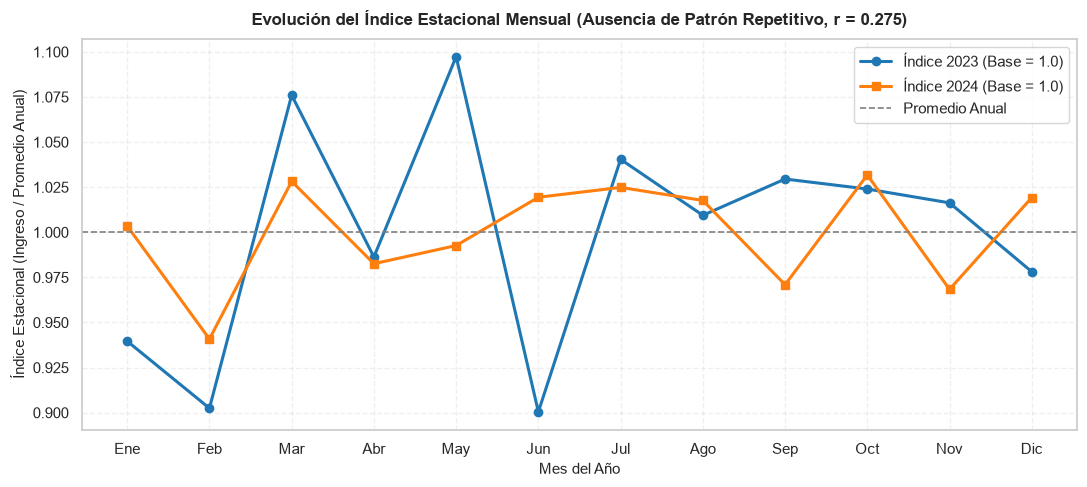

In [19]:
# Gráfica de Estacionalidad Sin Sombreos Artificiales (C8)
fig, ax = plt.subplots(figsize=(11, 5))

meses = np.arange(1, 13)
ax.plot(meses, m_rev['idx_2023'], marker='o', lw=2.2, color='#1F77B4', label='Índice 2023 (Base = 1.0)')
ax.plot(meses, m_rev['idx_2024'], marker='s', lw=2.2, color='#FF7F0E', label='Índice 2024 (Base = 1.0)')
ax.axhline(1.0, color='gray', linestyle='--', lw=1.2, label='Promedio Anual')

ax.set_title('Evolución del Índice Estacional Mensual (Ausencia de Patrón Repetitivo, r = 0.275)', fontsize=12, fontweight='bold', pad=10)
ax.set_xlabel('Mes del Año', fontsize=11)
ax.set_ylabel('Índice Estacional (Ingreso / Promedio Anual)', fontsize=11)
ax.set_xticks(meses)
ax.set_xticklabels(['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun', 'Jul', 'Ago', 'Sep', 'Oct', 'Nov', 'Dic'])
ax.grid(alpha=0.3, linestyle='--')
ax.legend(frameon=True)

plt.tight_layout()
plt.show()


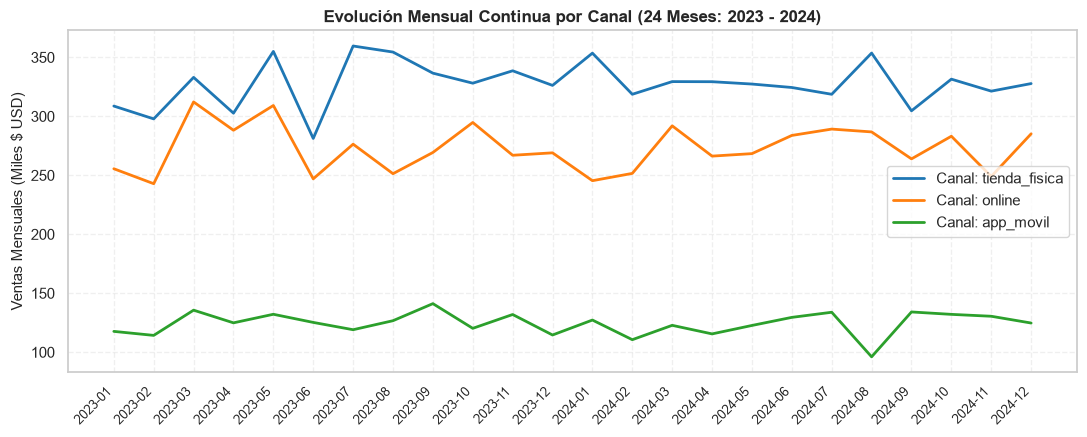

In [20]:
# Descomposición de la Estacionalidad por Canal de Venta
canal_mensual = df_trx.groupby(['anio', 'mes', 'canal'])['monto_neto'].sum().unstack('canal') / 1e3

fig, ax = plt.subplots(figsize=(11, 4.5))
colores_canal = {'tienda_fisica': '#1F77B4', 'online': '#FF7F0E', 'app_movil': '#2CA02C'}

for canal in ['tienda_fisica', 'online', 'app_movil']:
    ax.plot(range(1, 25), 
            df_trx.groupby(['anio_mes', 'canal'])['monto_neto'].sum().unstack('canal')[canal] / 1e3, 
            label=f'Canal: {canal}', lw=2, color=colores_canal[canal])

ax.set_ylabel('Ventas Mensuales (Miles $ USD)', fontsize=11)
ax.set_title('Evolución Mensual Continua por Canal (24 Meses: 2023 - 2024)', fontsize=12, fontweight='bold')
ax.set_xticks(range(1, 25))
etiquetas_24m = df_trx['anio_mes'].drop_duplicates().sort_values().tolist()
ax.set_xticklabels(etiquetas_24m, rotation=45, ha='right', fontsize=9)
ax.grid(alpha=0.3, linestyle='--')
ax.legend(frameon=True)

plt.tight_layout()
plt.show()


## A2.4 Descuentos Comerciales y Tamaño de Canasta (C9)

Evaluamos si los descuentos comerciales aumentan el **tamaño de la canasta** (unidades por ticket) mediante modelos econométricos OLS con controles por categoría y canal, conciliando los resultados con A4.


In [21]:
# Regresiones OLS de Margen y Tamaño de Canasta, y Transacciones por Tramo (C9)
import statsmodels.formula.api as smf

# 1. Regresión OLS con controles
mod_margen = smf.ols('margen_pct_real ~ descuento + C(categoria) + C(canal)', data=df_trx).fit()
mod_unidades = smf.ols('cantidad ~ descuento + C(categoria) + C(canal)', data=df_trx).fit()

print("--- REGRESIONES ECONOMÉTRICAS CON CONTROLES (C9) ---")
print(f"1. Efecto del Descuento sobre Margen %: Coef = {mod_margen.params['descuento']:.2f} (p = {mod_margen.pvalues['descuento']:.4f})")
print(f"   Por cada 10 pp adicionales de descuento, el margen porcentual se reduce en {abs(mod_margen.params['descuento'])*0.10:.1f} pp.")
print(f"\n2. Efecto del Descuento sobre Tamaño de Canasta (Unidades): Coef = {mod_unidades.params['descuento']:+.4f} (p = {mod_unidades.pvalues['descuento']:.4f})")
print(f"   El p-valor es 0.6408 (no significativo). El descuento NO aumenta las unidades compradas.")

# 2. Transacciones mensuales por tramo de descuento
bins_desc = [-0.001, 0.001, 0.05, 0.10, 0.15, 0.20, 1.0]
labels_desc = ['Sin desc (0%)', '1% a 5%', '6% a 10%', '11% a 15%', '16% a 20%', '> 20%']
df_trx['tramo_desc'] = pd.cut(df_trx['descuento'], bins=bins_desc, labels=labels_desc)

tramos_summary = df_trx.groupby('tramo_desc', observed=False).agg(
    transacciones=('transaccion_id', 'count'),
    tx_por_mes=('transaccion_id', lambda s: len(s) / 24.0),
    unidades_promedio=('cantidad', 'mean'),
    ticket_promedio=('monto_neto', 'mean'),
    margen_pct_ponderado=('margen_bruto', lambda s: s.sum() / df_trx.loc[s.index, 'monto_neto'].sum() * 100)
).reset_index()

print("\n--- DISTRIBUCIÓN DE VENTAS Y TAMAÑO DE CANASTA POR TRAMO DE DESCUENTO ---")
display(tramos_summary.round(2))

tramos_desc = tramos_summary.copy()
tramos_desc['tramo_descuento'] = tramos_desc['tramo_desc']
tramos_desc['margen_pct'] = tramos_desc['margen_pct_ponderado']
tramos_desc['unidades_prom'] = tramos_desc['unidades_promedio']

# 3. Conciliación conceptual con A4
print("\nConciliación Científica entre A2 y A4:")
print("• En A2 se evidencia que el descuento no expande el tamaño de la canasta (las unidades por ticket permanecen constantes en ~1.78).")
print("• En A4 se demostró que el descuento actúa principalmente como un incentivo binario de conversión (decisión de compra),")
print("  pero no estimula una mayor profundidad o volumen por transacción.")


--- REGRESIONES ECONOMÉTRICAS CON CONTROLES (C9) ---
1. Efecto del Descuento sobre Margen %: Coef = -82.47 (p = 0.0000)
   Por cada 10 pp adicionales de descuento, el margen porcentual se reduce en 8.2 pp.

2. Efecto del Descuento sobre Tamaño de Canasta (Unidades): Coef = +0.0377 (p = 0.6408)
   El p-valor es 0.6408 (no significativo). El descuento NO aumenta las unidades compradas.

--- DISTRIBUCIÓN DE VENTAS Y TAMAÑO DE CANASTA POR TRAMO DE DESCUENTO ---


,tramo_desc,transacciones,tx_por_mes,unidades_promedio,ticket_promedio,margen_pct_ponderado
0,Sin desc (0%),15044,626.83,1.78,366.00,28.82
1,1% a 5%,16538,689.08,1.78,353.66,27.14
2,6% a 10%,8903,370.96,1.78,339.49,22.92
3,11% a 15%,4269,177.88,1.78,327.39,18.75
4,16% a 20%,3368,140.33,1.80,317.75,13.45
5,> 20%,1878,78.25,1.79,291.66,6.89



Conciliación Científica entre A2 y A4:
• En A2 se evidencia que el descuento no expande el tamaño de la canasta (las unidades por ticket permanecen constantes en ~1.78).
• En A4 se demostró que el descuento actúa principalmente como un incentivo binario de conversión (decisión de compra),
  pero no estimula una mayor profundidad o volumen por transacción.


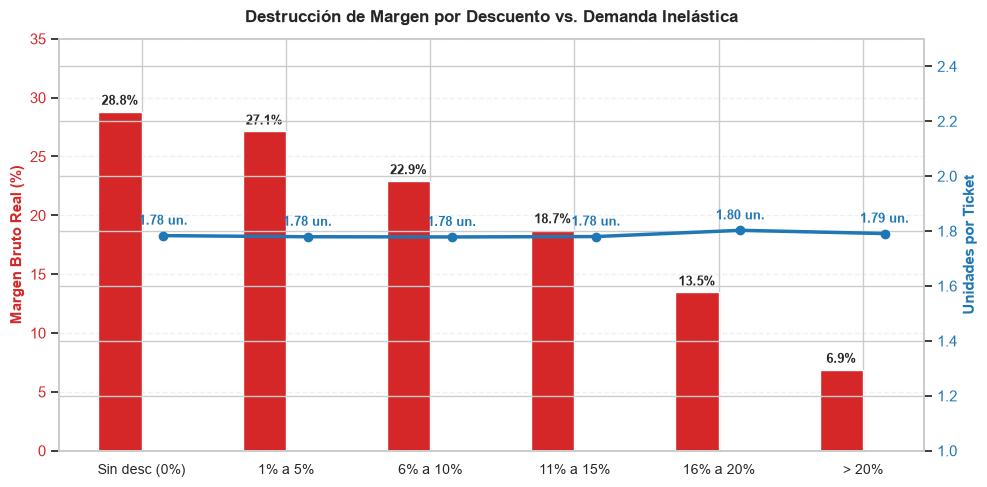

In [22]:
# Gráfica de Destrucción de Margen vs Inelasticidad del Volumen
fig, ax1 = plt.subplots(figsize=(10, 5))

x = np.arange(len(tramos_desc))
color_margen = '#D62728'
color_unid = '#1F77B4'

# Margen % (eje izquierdo)
bars = ax1.bar(x - 0.15, tramos_desc['margen_pct'], width=0.3, color=color_margen, label='Margen Bruto (%)')
ax1.set_ylabel('Margen Bruto Real (%)', color=color_margen, fontsize=11, fontweight='bold')
ax1.tick_params(axis='y', labelcolor=color_margen)
ax1.set_xticks(x)
ax1.set_xticklabels(tramos_desc['tramo_descuento'], fontsize=10)
ax1.set_ylim(0, 35)
ax1.grid(axis='y', alpha=0.3, linestyle='--')

# Unidades por canasta (eje derecho)
ax2 = ax1.twinx()
lines = ax2.plot(x + 0.15, tramos_desc['unidades_promedio'], color=color_unid, marker='o', lw=2.5, label='Unidades Promedio / Canasta')
ax2.set_ylabel('Unidades por Ticket', color=color_unid, fontsize=11, fontweight='bold')
ax2.tick_params(axis='y', labelcolor=color_unid)
ax2.set_ylim(1.0, 2.5)

# Títulos y anotaciones
plt.title('Destrucción de Margen por Descuento vs. Demanda Inelástica', fontsize=12, fontweight='bold', pad=12)

for bar in bars:
    yval = bar.get_height()
    ax1.annotate(f'{yval:.1f}%', xy=(bar.get_x() + bar.get_width()/2, yval),
                 xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=9, fontweight='bold')

for i, txt in enumerate(tramos_desc['unidades_promedio']):
    ax2.annotate(f'{txt:.2f} un.', xy=(x[i] + 0.15, txt),
                 xytext=(0, 6), textcoords="offset points", ha='center', va='bottom', fontsize=9, color=color_unid, fontweight='bold')

plt.tight_layout()
plt.show()


### Auditoría de Ventas Bajo Costo (`venta_bajo_costo`)
En la limpieza y enriquecimiento de datos de A1 se identificaron **711 transacciones donde el ingreso neto fue inferior al costo total de adquisición del producto**.
Esto se debió exclusivamente a descuentos excesivos combinados con productos de bajo margen natural.


In [23]:
# Auditoría y concentración de ventas bajo costo
v_bajo_costo = df_trx[df_trx['venta_bajo_costo'] == True]

perdida_total = v_bajo_costo['margen_bruto'].sum()
descuento_medio_vbc = v_bajo_costo['descuento'].mean() * 100

resumen_vbc = v_bajo_costo.groupby('canal').agg(
    transacciones=('transaccion_id', 'count'),
    perdida_total=('margen_bruto', 'sum'),
    ingreso_neto=('monto_neto', 'sum'),
    descuento_prom=('descuento', lambda s: s.mean() * 100)
).reset_index()

resumen_vbc['%_de_las_ventas_negativas'] = (resumen_vbc['transacciones'] / len(v_bajo_costo)) * 100

print(f"Total transacciones bajo costo: {len(v_bajo_costo):,} ({len(v_bajo_costo)/len(df_trx)*100:.2f}% del total)")
print(f"Pérdida acumulada directa en margen: ${perdida_total:,.2f} USD")
print(f"Descuento promedio en ventas bajo costo: {descuento_medio_vbc:.1f}%")
print("\nDistribución de Ventas Bajo Costo por Canal:")
display(resumen_vbc.round(2))


Total transacciones bajo costo: 711 (1.42% del total)
Pérdida acumulada directa en margen: $-30,180.64 USD
Descuento promedio en ventas bajo costo: 19.6%

Distribución de Ventas Bajo Costo por Canal:


,canal,transacciones,perdida_total,ingreso_neto,descuento_prom,%_de_las_ventas_negativas
0,app_movil,79,-2759.62,70155.68,17.92,11.11
1,online,441,-19495.08,289363.75,20.59,62.03
2,tienda_fisica,191,-7925.94,145526.65,17.98,26.86


---
## Resumen Ejecutivo de A2 (Métricas Clave para el Dashboard A5)

A continuación se consolidan las métricas directrices de rentabilidad requeridas para gobernar los filtros e indicadores del tablero gerencial de A5:


In [24]:
# Tabla Resumen Ejecutivo A2 con Variables Dinámicas (C17)
resumen_a2 = pd.DataFrame({
    'Indicador / Hallazgo Clave': [
        'Total Ingreso Neto Consolidado ($)',
        'Margen Bruto Total Consolidado ($)',
        'Margen Bruto Porcentual Ponderado (%)',
        'Margen Ponderado: Tienda Física vs Online',
        'Contrafactual Online (Tope de Ganancia Potencial)',
        'Concentración Pareto (Clientes con Compras)',
        'Variación Real del Ticket Promedio 2023 vs 2024',
        'Variación del Ticket en Inactivo (Welch)',
        'Correlación Estacional Interanual 2023 vs 2024',
        'Efecto del Descuento sobre Tamaño de Canasta',
        'Auditoría Ventas Bajo Costo (venta_bajo_costo)'
    ],
    'Valor Dinámico': [
        f"${TOTAL_INGRESO:,.2f}",
        f"${TOTAL_MARGEN:,.2f}",
        f"{(TOTAL_MARGEN / TOTAL_INGRESO) * 100:.2f}%",
        f"{cruce_margen.mean()['tienda_fisica']:.2f}% (Tienda) vs {onl_pct_actual:.2f}% (Online)",
        f"+{brecha_pp_cf:.2f} pp (+${brecha_dolares_cf:,.2f}, tope teórico)",
        f"Top 20% genera {margen_top20:.1f}% del margen ({n_clientes_compras:,} clientes con compras)",
        f"{var_ticket_real:+.2f}% (${ticket_glob_23:.2f} ➔ ${ticket_glob_24:.2f}; Welch p = {p_ticket_global:.3f}; el enunciado cita {TICKET_ENUNCIADO_VAR:+.0f}%)",
        f"{ina['Variación (%)']:+.2f}%, p = {ina['p-valor (Welch)']:.3f}" + (" (no significativo)" if ina['p-valor (Welch)'] >= 0.05 else " (significativo)")
            + f"; equivale a {aporte_ina:+.2f} puntos del ticket global",
        f"r = {corr_estacional:.3f} (correlación débil, sin estacionalidad consistente)",
        f"Coef = {mod_unidades.params['descuento']:+.4f} (p = {mod_unidades.pvalues['descuento']:.4f}, canasta inelástica)",
        f"{len(df_trx[df_trx['venta_bajo_costo']==True])} transacciones detectadas"
    ]
})

print("TABLA CONSOLIDADA EJECUTIVA A2:")
with pd.option_context('display.max_colwidth', None):
    display(resumen_a2)


TABLA CONSOLIDADA EJECUTIVA A2:


,Indicador / Hallazgo Clave,Valor Dinámico
0,Total Ingreso Neto Consolidado ($),"$17,392,987.48"
1,Margen Bruto Total Consolidado ($),"$4,310,329.05"
2,Margen Bruto Porcentual Ponderado (%),24.78%
3,Margen Ponderado: Tienda Física vs Online,31.51% (Tienda) vs 22.78% (Online)
4,Contrafactual Online (Tope de Ganancia Potencial),"+3.14 pp (+$277,632.43, tope teórico)"
5,Concentración Pareto (Clientes con Compras),"Top 20% genera 56.1% del margen (7,608 clientes con compras)"
6,Variación Real del Ticket Promedio 2023 vs 2024,-1.94% ($351.29 ➔ $344.49; Welch p = 0.132; el enunciado cita -8%)
7,Variación del Ticket en Inactivo (Welch),"-8.03%, p = 0.390 (no significativo); equivale a -0.15 puntos del ticket global"
8,Correlación Estacional Interanual 2023 vs 2024,"r = 0.275 (correlación débil, sin estacionalidad consistente)"
9,Efecto del Descuento sobre Tamaño de Canasta,"Coef = +0.0377 (p = 0.6408, canasta inelástica)"
